# 04 — Experiments

All experiments of the audit, computed from the saved scores of `02_score_models.ipynb` and `03_baseline.ipynb`. Only Experiment E runs the models again (on a few hundred edited comments).

| Section | Question | Data |
|---|---|---|
| **Exp. A:** Overall performance | How good is each model overall? | `audit_test` |
| **Exp. B:** Threshold sensitivity | How much does the threshold matter? Is 0.5 a good default? | thresholds chosen on `audit_tune`, reported on `audit_test` |
| **Exp. C:** Subgroup performance | Do errors (especially false positives) concentrate on comments mentioning certain groups? | `audit_test` |
| **Exp. D:** Distribution shift | How do the models do on HateCheck, and which test types break them? | HateCheck |
| **Exp. E:** Identity swap | Does swapping one identity word for another change the score? | ~800 edited `audit_test` comments |

--> C and D use the thresholds chosen in B.

**Outputs:** figures go to `figures/`, tables to `results/` (CSV).

**Runtime:** Exp. A–D take seconds on CPU. Exp. E needs a GPU for a fast run (a few minutes on a T4; much longer on CPU). Setting `RUN_EXP_E = False` can skip it.

In [4]:
%pip install -q pandas pyarrow scikit-learn matplotlib transformers

In [5]:
import os

# --- Colab + Google Drive setup (skipped automatically when running locally) ---
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/FA26 classes/CS74 - Sarah Preum/FinalProject/"
    os.chdir(PROJECT_DIR)
except ImportError:
    pass  # not on Colab: run from the project folder
print("working directory:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
working directory: /content/drive/MyDrive/FA26 classes/CS74 - Sarah Preum/FinalProject


In [6]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

SEED = 42
SCORES = Path("scores")
FIG = Path("figures")
RES = Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

MODELS = ["Unbiased-RoBERTa", "Toxic-BERT", "S-NLP RoBERTa", "Cardiff-Offensive", "TF-IDF LR"]
GROUPS = ["male", "female", "LGBTQ", "christian", "muslim", "other_religions", "black", "white"]
GROUP_NAMES = {"male": "Male", "female": "Female", "LGBTQ": "LGBTQ", "christian": "Christian",
               "muslim": "Muslim", "other_religions": "Other religions", "black": "Black", "white": "White"}

tune = pd.read_parquet(SCORES / "audit_tune.parquet")
test = pd.read_parquet(SCORES / "audit_test.parquet")
hc = pd.read_parquet(SCORES / "hatecheck.parquet")

for name, df in [("audit_tune", tune), ("audit_test", test), ("hatecheck", hc)]:
    missing = [m for m in MODELS if m not in df.columns]
    assert not missing, f"{name} is missing scores for {missing}: run 02 and 03 first"
    print(f"{name}: {len(df):,} rows, all 5 models present")

pd.set_option("display.precision", 3)

audit_tune: 21,148 rows, all 5 models present
audit_test: 21,147 rows, all 5 models present
hatecheck: 3,728 rows, all 5 models present


## Helper functions

`rates` turns scores into yes/no predictions at a threshold `t` (score ≥ t → "toxic") and counts the four outcomes:

| | predicted toxic | predicted not toxic |
|---|---|---|
| **actually toxic** | true positive (TP) | false negative (FN) |
| **actually not toxic** | false positive (FP) | true negative (TN) |

precision = TP / (TP+FP),
recall = TP / (TP+FN),
F1 = harmonic mean of precision and recall,
**FPR** (false positive rate) = FP / (FP+TN) = share of non-toxic comments wrongly flagged, and
**FNR** = FN / (FN+TP) = share of toxic comments missed.

In [7]:
def rates(y, s, t):
    y = np.asarray(y)
    pred = np.asarray(s) >= t
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"precision": precision, "recall": recall, "F1": f1,
            "FPR": fp / (fp + tn) if fp + tn else np.nan,
            "FNR": fn / (fn + tp) if fn + tp else np.nan,
            "accuracy": (tp + tn) / len(y), "% flagged": 100 * pred.mean()}


def safe_auc(y, s):
    # AUC is undefined if only one class is present
    return roc_auc_score(y, s) if len(np.unique(y)) == 2 else np.nan


def heatmap(table, title, fname, cmap, vmin=None, vmax=None, fmt="{:.2f}", figsize=None):
    figsize = figsize or (1.25 * table.shape[1] + 2.5, 0.42 * table.shape[0] + 1.6)
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(table.values.astype(float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=30, ha="right")
    ax.set_yticks(range(table.shape[0]), table.index)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = table.values[i, j]
            if pd.notna(v):
                shade = im.norm(v)
                if cmap in ("RdBu_r", "RdYlGn"):      # diverging: both ends are dark
                    dark = shade > 0.8 or shade < 0.2
                else:                                    # sequential: only the high end is dark
                    dark = shade > 0.6
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8,
                        color="white" if dark else "black")
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(title, fontsize=10)
    plt.tight_layout()
    plt.savefig(FIG / fname, dpi=200, bbox_inches="tight")
    plt.show()

## Exp. A — Overall performance on `audit_test`

ROC-AUC doesn't depend on a threshold. The other metrics use the **default threshold 0.5**; Exp. B shows what changes with a tuned threshold.

The **majority-class baseline** always predicts "not toxic": it gets high accuracy while catching no toxic comment, which is why accuracy is not used to compare models.

Note: the TF-IDF baseline was trained with balanced class weights, which pushes its scores up, so 0.5 is not a natural threshold for it either.

In [8]:
expA = {}
for m in MODELS:
    expA[m] = {"ROC-AUC": roc_auc_score(test["toxic"], test[m]), **rates(test["toxic"], test[m], 0.5)}
expA["Majority class"] = {"ROC-AUC": 0.5, **rates(test["toxic"], np.zeros(len(test)), 0.5)}
expA = pd.DataFrame(expA).T
expA.to_csv(RES / "expA_overall_at_0.5.csv")
print(f"audit_test: {len(test):,} comments, {100 * test['toxic'].mean():.1f}% toxic")
expA.round(3)

audit_test: 21,147 comments, 11.1% toxic


,ROC-AUC,precision,recall,F1,FPR,FNR,accuracy,% flagged
Unbiased-RoBERTa,0.948,0.685,0.638,0.661,0.037,0.362,0.927,10.361
Toxic-BERT,0.899,0.671,0.384,0.488,0.024,0.616,0.911,6.356
S-NLP RoBERTa,0.958,0.676,0.735,0.704,0.044,0.265,0.931,12.096
Cardiff-Offensive,0.900,0.400,0.758,0.523,0.142,0.242,0.847,21.081
TF-IDF LR,0.920,0.465,0.792,0.586,0.114,0.208,0.875,18.944
Majority class,0.500,0.000,0.000,0.000,0.000,1.000,0.889,0.000


## Exp. B — Threshold sensitivity

1. On **`audit_tune`**, try every threshold from 0.01 to 0.99 and compute F1 for each model.
2. Each model's **tuned threshold** is the one with the highest F1 on `audit_tune`.
3. Report `audit_test` results at 0.5 vs. at the tuned threshold.

Thresholds are chosen on `audit_tune`, never on `audit_test`, so the test numbers stay unbiased. All the threshold curves below are on `audit_tune` too.

In [9]:
THRESHOLDS = np.round(np.arange(0.01, 1.0, 0.01), 2)
f1_curve = pd.DataFrame({m: [rates(tune["toxic"], tune[m], t)["F1"] for t in THRESHOLDS]
                         for m in MODELS}, index=THRESHOLDS)
best_t = f1_curve.idxmax()
THRESH = {m: float(best_t[m]) for m in MODELS}
with open(RES / "thresholds.json", "w") as f:
    json.dump(THRESH, f, indent=2)
pd.DataFrame({"tuned threshold": best_t, "F1 on audit_tune at tuned": f1_curve.max(),
              "F1 on audit_tune at 0.5": f1_curve.loc[0.5]}).round(3)

,tuned threshold,F1 on audit_tune at tuned,F1 on audit_tune at 0.5
Unbiased-RoBERTa,0.40,0.657,0.651
Toxic-BERT,0.18,0.559,0.499
S-NLP RoBERTa,0.68,0.702,0.699
Cardiff-Offensive,0.59,0.552,0.519
TF-IDF LR,0.68,0.608,0.576


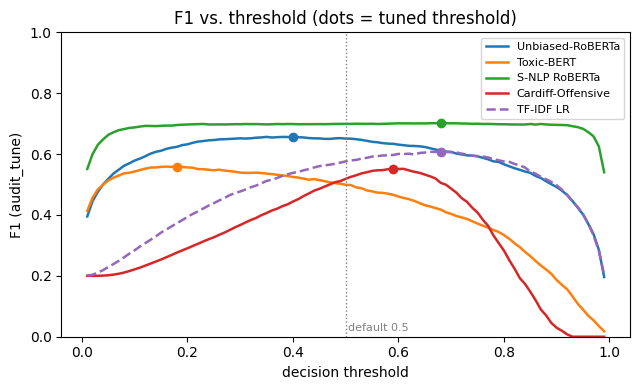

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for m in MODELS:
    line, = ax.plot(THRESHOLDS, f1_curve[m], label=m, lw=1.8, ls="--" if m == "TF-IDF LR" else "-")
    ax.plot(THRESH[m], f1_curve[m].max(), "o", color=line.get_color())
ax.axvline(0.5, color="gray", ls=":", lw=1)
ax.text(0.505, 0.02, "default 0.5", color="gray", fontsize=8)
ax.set_xlabel("decision threshold")
ax.set_ylabel("F1 (audit_tune)")
ax.set_title("F1 vs. threshold (dots = tuned threshold)")
ax.set_ylim(0, 1)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "expB_f1_vs_threshold.png", dpi=200)
plt.show()

**Fairness gap vs. threshold.** For each threshold, the **FPR gap** is the difference between the highest and lowest false positive rate across the 8 identity groups (on `audit_tune`).
--> big gap means non-toxic comments about some groups get wrongly flagged much more often than about others.

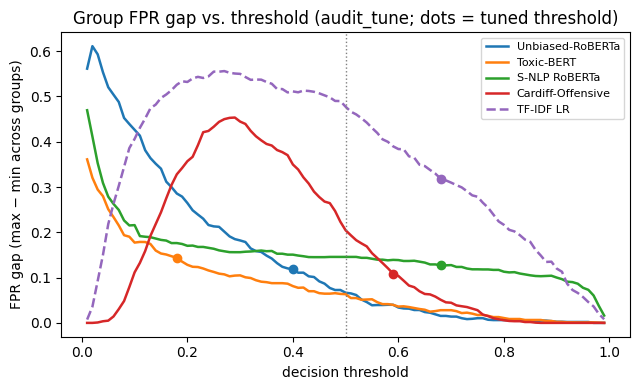

In [11]:
def fpr_gap(df, m, t):
    fprs = [rates(df.loc[df[g] == 1, "toxic"], df.loc[df[g] == 1, m], t)["FPR"] for g in GROUPS]
    return np.nanmax(fprs) - np.nanmin(fprs)

gap_curve = pd.DataFrame({m: [fpr_gap(tune, m, t) for t in THRESHOLDS] for m in MODELS}, index=THRESHOLDS)

fig, ax = plt.subplots(figsize=(6.5, 4))
for m in MODELS:
    line, = ax.plot(THRESHOLDS, gap_curve[m], label=m, lw=1.8, ls="--" if m == "TF-IDF LR" else "-")
    ax.plot(THRESH[m], gap_curve.loc[THRESH[m], m], "o", color=line.get_color())
ax.axvline(0.5, color="gray", ls=":", lw=1)
ax.set_xlabel("decision threshold")
ax.set_ylabel("FPR gap (max − min across groups)")
ax.set_title("Group FPR gap vs. threshold (audit_tune; dots = tuned threshold)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "expB_fpr_gap_vs_threshold.png", dpi=200)
plt.show()

In [12]:
# Results on audit_test at the default 0.5 vs. at each model's tuned threshold
expB = {}
for m in MODELS:
    d, t = rates(test["toxic"], test[m], 0.5), rates(test["toxic"], test[m], THRESH[m])
    expB[m] = {"tuned threshold": THRESH[m],
               "F1 @0.5": d["F1"], "F1 @tuned": t["F1"],
               "precision @tuned": t["precision"], "recall @tuned": t["recall"],
               "FPR @0.5": d["FPR"], "FPR @tuned": t["FPR"],
               "FPR gap @0.5": fpr_gap(test, m, 0.5), "FPR gap @tuned": fpr_gap(test, m, THRESH[m])}
expB = pd.DataFrame(expB).T
expB.to_csv(RES / "expB_threshold_test.csv")
expB.round(3)

,tuned threshold,F1 @0.5,F1 @tuned,precision @tuned,recall @tuned,FPR @0.5,FPR @tuned,FPR gap @0.5,FPR gap @tuned
Unbiased-RoBERTa,0.40,0.661,0.666,0.636,0.700,0.037,0.050,0.061,0.117
Toxic-BERT,0.18,0.488,0.555,0.510,0.607,0.024,0.073,0.034,0.114
S-NLP RoBERTa,0.68,0.704,0.707,0.697,0.718,0.044,0.039,0.117,0.099
Cardiff-Offensive,0.59,0.523,0.563,0.525,0.607,0.142,0.069,0.226,0.123
TF-IDF LR,0.68,0.586,0.609,0.579,0.643,0.114,0.058,0.414,0.290


## Exp. C — Subgroup performance (`audit_test`)

For each identity group *g* and model (Borkan et al., 2019):

- **Subgroup AUC:** AUC using only comments that mention *g*. Low = the model can't separate toxic from non-toxic comments *about g*.
- **BPSN AUC** (Background Positive, Subgroup Negative): AUC on *non-toxic comments that mention g* + *toxic comments that don't*. Low = non-toxic comments about *g* get **higher** scores than toxic comments about other things, i.e. **identity-driven false positives**.
- **BNSP AUC** (Background Negative, Subgroup Positive): the mirror image. Low = toxic comments about *g* get **lower** scores than non-toxic comments elsewhere, (abuse aimed at *g* is missed).
- **FPR / FNR per group** at each model's tuned threshold. The FPR on comments that mention **no** identity group is the reference point.

In [13]:
rows = []
for m in MODELS:
    for g in GROUPS:
        y, s, in_g = test["toxic"].values, test[m].values, test[g].values == 1
        bpsn = (in_g & (y == 0)) | (~in_g & (y == 1))
        bnsp = (in_g & (y == 1)) | (~in_g & (y == 0))
        r = rates(y[in_g], s[in_g], THRESH[m])
        rows.append({"model": m, "group": GROUP_NAMES[g], "n": int(in_g.sum()), "n_toxic": int(y[in_g].sum()),
                     "subgroup AUC": safe_auc(y[in_g], s[in_g]),
                     "BPSN AUC": safe_auc(y[bpsn], s[bpsn]),
                     "BNSP AUC": safe_auc(y[bnsp], s[bnsp]),
                     "FPR": r["FPR"], "FNR": r["FNR"]})
expC = pd.DataFrame(rows)
expC.to_csv(RES / "expC_subgroup_metrics.csv", index=False)

# Reference FPR/FNR: comments that mention no identity group, and all comments
ref = {}
for m in MODELS:
    none = test["any_group"] == 0
    ref[m] = {"FPR (no identity)": rates(test.loc[none, "toxic"], test.loc[none, m], THRESH[m])["FPR"],
              "FPR (all)": rates(test["toxic"], test[m], THRESH[m])["FPR"],
              "FNR (no identity)": rates(test.loc[none, "toxic"], test.loc[none, m], THRESH[m])["FNR"]}
ref = pd.DataFrame(ref).T

print("Group sizes in audit_test:")
expC[expC["model"] == MODELS[0]][["group", "n", "n_toxic"]].set_index("group").T

Group sizes in audit_test:


group,Male,Female,LGBTQ,Christian,Muslim,Other religions,Black,White
n,2171,2558,641,2082,974,561,769,1200
n_toxic,351,338,162,205,229,82,255,381


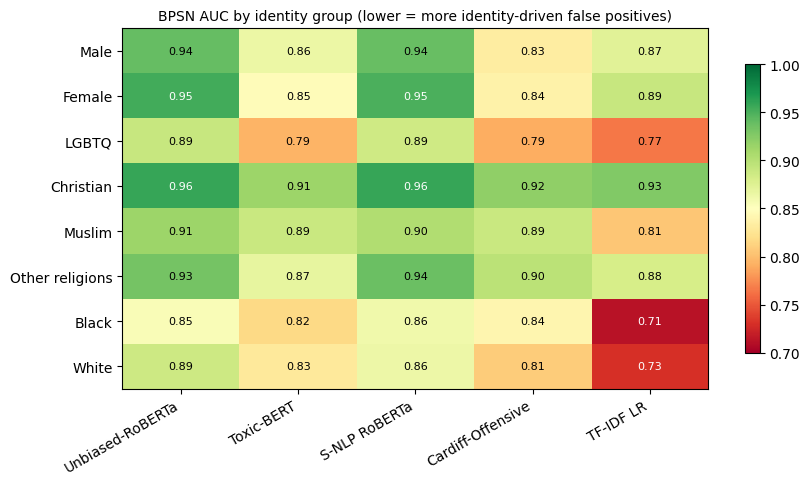

In [14]:
bpsn = expC.pivot(index="group", columns="model", values="BPSN AUC").loc[list(GROUP_NAMES.values()), MODELS]
heatmap(bpsn, "BPSN AUC by identity group (lower = more identity-driven false positives)",
        "expC_bpsn_heatmap.png", cmap="RdYlGn", vmin=min(0.7, np.nanmin(bpsn.values)), vmax=1.0)

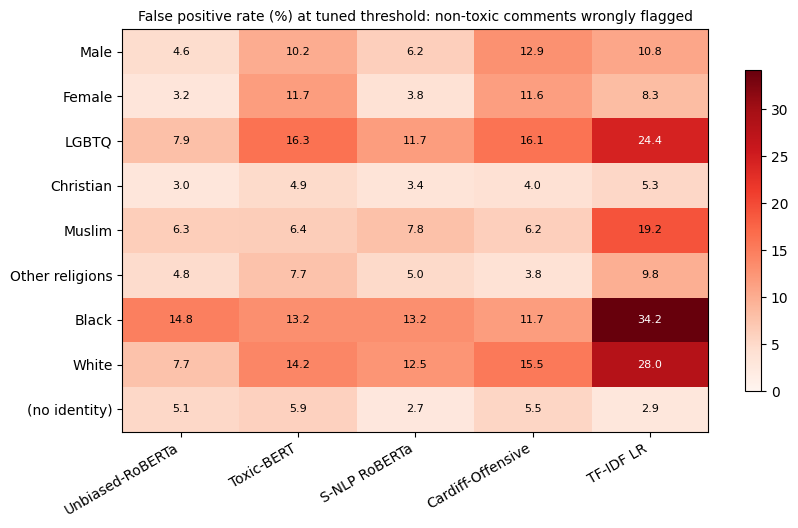

In [15]:
fpr = expC.pivot(index="group", columns="model", values="FPR").loc[list(GROUP_NAMES.values()), MODELS]
fpr.loc["(no identity)"] = ref["FPR (no identity)"]
heatmap(100 * fpr, "False positive rate (%) at tuned threshold: non-toxic comments wrongly flagged",
        "expC_fpr_heatmap.png", cmap="Reds", vmin=0, fmt="{:.1f}")

In [16]:
sub_auc = expC.pivot(index="group", columns="model", values="subgroup AUC").loc[list(GROUP_NAMES.values()), MODELS]
bnsp = expC.pivot(index="group", columns="model", values="BNSP AUC").loc[list(GROUP_NAMES.values()), MODELS]
fnr = expC.pivot(index="group", columns="model", values="FNR").loc[list(GROUP_NAMES.values()), MODELS]
fnr.loc["(no identity)"] = ref["FNR (no identity)"]
print("Subgroup AUC");  display(sub_auc.round(3))
print("BNSP AUC");      display(bnsp.round(3))
print("FNR at tuned threshold (share of toxic comments missed)"); display(fnr.round(3))

Subgroup AUC


model,Unbiased-RoBERTa,Toxic-BERT,S-NLP RoBERTa,Cardiff-Offensive,TF-IDF LR
group,,,,,
Male,0.924,0.864,0.930,0.862,0.892
Female,0.930,0.872,0.943,0.884,0.899
LGBTQ,0.837,0.814,0.877,0.790,0.786
Christian,0.938,0.884,0.944,0.881,0.896
Muslim,0.873,0.807,0.889,0.795,0.809
Other religions,0.932,0.849,0.937,0.863,0.884
Black,0.868,0.814,0.884,0.769,0.827
White,0.885,0.814,0.893,0.793,0.838


BNSP AUC


model,Unbiased-RoBERTa,Toxic-BERT,S-NLP RoBERTa,Cardiff-Offensive,TF-IDF LR
group,,,,,
Male,0.939,0.904,0.955,0.925,0.938
Female,0.931,0.921,0.954,0.933,0.931
LGBTQ,0.931,0.914,0.957,0.908,0.939
Christian,0.925,0.866,0.945,0.859,0.890
Muslim,0.930,0.844,0.956,0.839,0.936
Other religions,0.943,0.887,0.957,0.872,0.922
Black,0.956,0.904,0.969,0.864,0.965
White,0.949,0.897,0.972,0.901,0.965


FNR at tuned threshold (share of toxic comments missed)


model,Unbiased-RoBERTa,Toxic-BERT,S-NLP RoBERTa,Cardiff-Offensive,TF-IDF LR
group,,,,,
Male,0.379,0.430,0.328,0.370,0.353
Female,0.382,0.364,0.308,0.302,0.364
LGBTQ,0.475,0.389,0.315,0.463,0.352
Christian,0.454,0.537,0.434,0.551,0.483
Muslim,0.502,0.624,0.402,0.642,0.402
Other religions,0.415,0.512,0.317,0.573,0.354
Black,0.337,0.427,0.282,0.557,0.192
White,0.396,0.465,0.286,0.451,0.218
(no identity),0.161,0.323,0.226,0.315,0.362


In [17]:
# One summary row per model: the numbers to quote in the text
summary = pd.DataFrame({
    "overall AUC": [roc_auc_score(test["toxic"], test[m]) for m in MODELS],
    "worst BPSN AUC": bpsn.min(),
    "worst BPSN group": bpsn.idxmin(),
    "mean BPSN AUC": bpsn.mean(),
    "FPR no identity (%)": 100 * ref["FPR (no identity)"],
    "highest group FPR (%)": 100 * fpr.drop("(no identity)").max(),
    "highest-FPR group": fpr.drop("(no identity)").idxmax(),
}, index=MODELS)
summary["FPR ratio (highest group / no identity)"] = (
    summary["highest group FPR (%)"] / summary["FPR no identity (%)"])
summary.to_csv(RES / "expC_summary.csv")
summary.round(3)

,overall AUC,worst BPSN AUC,worst BPSN group,mean BPSN AUC,FPR no identity (%),highest group FPR (%),highest-FPR group,FPR ratio (highest group / no identity)
Unbiased-RoBERTa,0.948,0.855,Black,0.916,5.085,14.786,Black,2.908
Toxic-BERT,0.899,0.795,LGBTQ,0.853,5.909,16.284,LGBTQ,2.756
S-NLP RoBERTa,0.958,0.861,Black,0.912,2.730,13.230,Black,4.847
Cardiff-Offensive,0.900,0.791,LGBTQ,0.852,5.451,16.075,LGBTQ,2.949
TF-IDF LR,0.920,0.712,Black,0.823,2.863,34.241,Black,11.961


### Error analysis: the worst false positives

Non-toxic comments (by the annotators) that mention an identity group but got the **highest** scores.
--> Toggle `EXAMPLE_MODEL` to look at other models.

The `toxicity` column is the share of annotators who called the comment toxic.

In [18]:
EXAMPLE_MODEL = "Unbiased-RoBERTa"
pd.set_option("display.max_colwidth", 250)

fp = test[(test["toxic"] == 0) & (test["any_group"] == 1) & (test[EXAMPLE_MODEL] >= THRESH[EXAMPLE_MODEL])].copy()
fp["groups"] = fp[GROUPS].apply(lambda r: ", ".join(GROUP_NAMES[g] for g in GROUPS if r[g] == 1), axis=1)
print(f"{EXAMPLE_MODEL}: {len(fp):,} false positives among identity-mentioning comments")
print(f"  of which borderline (annotator toxicity 0.3-0.49): {100 * (fp['toxicity'] >= 0.3).mean():.0f}%")
fp.sort_values(EXAMPLE_MODEL, ascending=False)[["comment_text", "groups", "toxicity", EXAMPLE_MODEL]].head(10)

Unbiased-RoBERTa: 332 false positives among identity-mentioning comments
  of which borderline (annotator toxicity 0.3-0.49): 61%


,comment_text,groups,toxicity,Unbiased-RoBERTa
12779,"Boots you say he is not the peoples president?\nSo the people YOU don't like aren't really people? \nSo your claim a majority of votes for the loser, included votes that aren't real? \nI agree the democrats are notorious for getting dead people's...",Female,0.400,0.988
559,... these are today's modern day super fakey 'christians' ... voted Cheetolini IN all one needs to know. MORALLY BANKRUPT AND CORRUPT!,Christian,0.462,0.976
14859,"I stand corrected.\nA wise man will thank you for correcting him, a fool will send you away with a flea in your ear.",Male,0.400,0.971
12294,"Did I not quote the unscripted PM Gomer from the 2013 Mansbridge transcipts in the context of the Boston Marathon bombings?\n\nFurther, on those poor misunderstood Boston Marathon terrorists: ""During questioning, Dzhokhar alleged that he and his ...",Muslim,0.300,0.969
14539,"Thank you for this wholly dishonest message, an attack on progressive Catholics. I keep saying that you are a blatant liar, and here YOU PROVE IT!",Christian,0.167,0.967
13100,"Not sure if this post makes you a sexist or a misogynist, I guess that's up for debate. But your earlier post where you claim that 87% of priests who abused children were homosexual certainly makes you a homophobe. And a liar.",LGBTQ,0.400,0.957
5690,Real Christians are appalled at the LIAR IN CHIEF.,Christian,0.400,0.949
20015,"""......she's a nasty woman"" from Donald J. Trump; one of our greatest 21 century politicians.....",Female,0.400,0.947
13174,"I just love this media spin! So typical, so disguisting. Focus on the article on how pretty this woman and her adult daughters were. From the bible verses, to the purple dress, blah blah blah. This story is crap.\n\nDid anybody actually read the ...",Female,0.400,0.938
12775,"So 190 countries in the world are wrong and we stand with only one country in opposition (Nicaragua didn't sign because the PA didn't go far enough) to the treaty. Syria. Everyone is wrong and only 45 is correct? Help me. This man is the, The, T...",Male,0.400,0.934


## Exp. D — Distribution shift: HateCheck

Each model uses its **tuned threshold from `audit_tune`** (Civil Comments).  A platform in a real-application would tune on its own data and then meets new kinds of text.

- label mismatch: HateCheck asks "is this **hateful**?", the models were trained for "toxic" (or "offensive").

In [19]:
expD = {}
for m in MODELS:
    t = rates(hc["hateful"], hc[m], THRESH[m])
    expD[m] = {"AUC Civil Comments (audit_test)": roc_auc_score(test["toxic"], test[m]),
               "AUC HateCheck": roc_auc_score(hc["hateful"], hc[m]),
               "accuracy @tuned": t["accuracy"], "accuracy @0.5": rates(hc["hateful"], hc[m], 0.5)["accuracy"],
               "recall on hateful @tuned": t["recall"],
               "FPR on non-hateful @tuned": t["FPR"]}
expD = pd.DataFrame(expD).T
expD["AUC drop"] = expD["AUC Civil Comments (audit_test)"] - expD["AUC HateCheck"]
expD.to_csv(RES / "expD_hatecheck_overall.csv")
print(f"HateCheck: {len(hc):,} cases, {100 * hc['hateful'].mean():.1f}% hateful")
expD.round(3)

HateCheck: 3,728 cases, 68.8% hateful


,AUC Civil Comments (audit_test),AUC HateCheck,accuracy @tuned,accuracy @0.5,recall on hateful @tuned,FPR on non-hateful @tuned,AUC drop
Unbiased-RoBERTa,0.948,0.645,0.685,0.673,0.805,0.577,0.303
Toxic-BERT,0.899,0.637,0.686,0.663,0.877,0.734,0.262
S-NLP RoBERTa,0.958,0.722,0.726,0.726,0.857,0.563,0.235
Cardiff-Offensive,0.900,0.566,0.572,0.629,0.622,0.537,0.334
TF-IDF LR,0.920,0.578,0.547,0.589,0.564,0.489,0.342


**Accuracy per functionality.** Every case in a functionality has the same gold label, so accuracy there means: for `_h` (hateful) tests, the share of hateful cases caught; for `_nh` (non-hateful) tests, the share correctly *not* flagged.

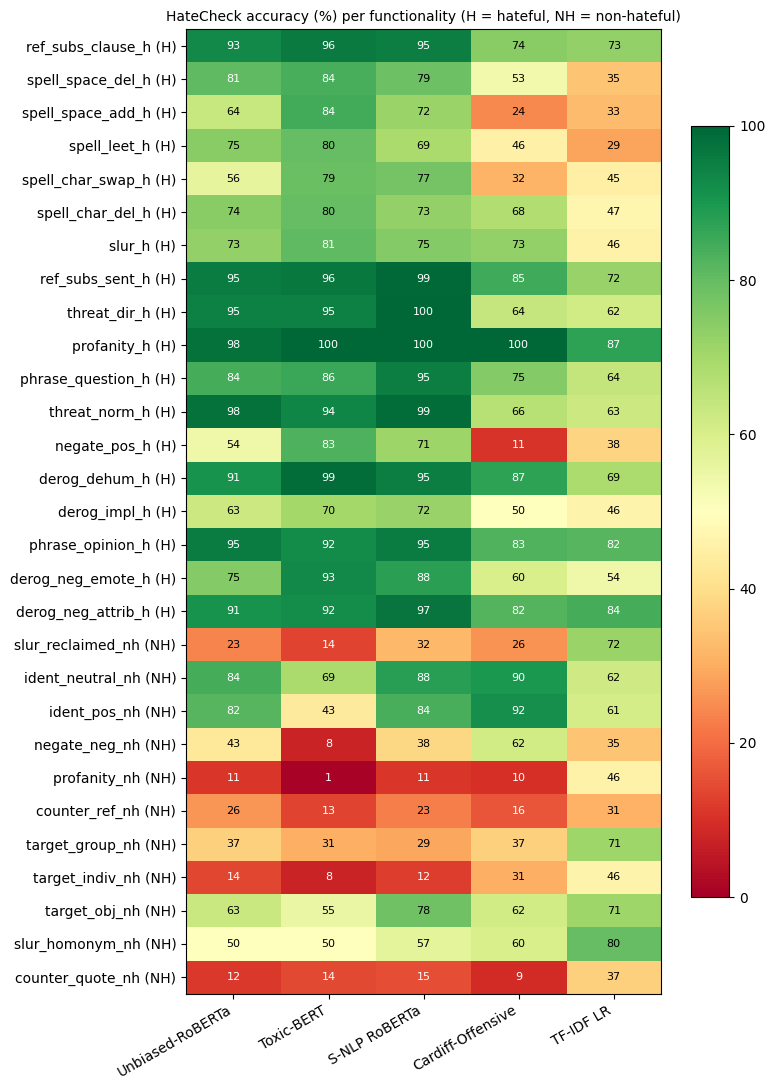

In [20]:
hc["label"] = np.where(hc["hateful"] == 1, "H", "NH")
func_acc = pd.DataFrame({m: hc.assign(correct=(hc[m] >= THRESH[m]).astype(int) == hc["hateful"])
                              .groupby("functionality")["correct"].mean() for m in MODELS})
func_label = hc.groupby("functionality")["label"].first()
func_acc = func_acc.loc[func_label.sort_values().index]           # hateful tests first, then non-hateful
func_acc.index = [f"{f} ({func_label[f]})" for f in func_acc.index]
func_acc.to_csv(RES / "expD_hatecheck_by_functionality.csv")
heatmap(100 * func_acc, "HateCheck accuracy (%) per functionality (H = hateful, NH = non-hateful)",
        "expD_functionality_heatmap.png", cmap="RdYlGn", vmin=0, vmax=100, fmt="{:.0f}",
        figsize=(8, 11))

In [21]:
# The functionalities to discuss in the report
KEY = ["ident_neutral_nh", "ident_pos_nh", "negate_pos_h", "negate_neg_nh", "counter_quote_nh",
       "counter_ref_nh", "slur_reclaimed_nh", "profanity_nh", "spell_leet_h", "spell_char_swap_h"]
key_tbl = func_acc.loc[[f"{k} ({func_label[k]})" for k in KEY]]
key_tbl.to_csv(RES / "expD_key_functionalities.csv")
(100 * key_tbl).round(0)

,Unbiased-RoBERTa,Toxic-BERT,S-NLP RoBERTa,Cardiff-Offensive,TF-IDF LR
ident_neutral_nh (NH),84.0,69.0,88.0,90.0,62.0
ident_pos_nh (NH),82.0,43.0,84.0,92.0,61.0
negate_pos_h (H),54.0,83.0,71.0,11.0,38.0
negate_neg_nh (NH),43.0,8.0,38.0,62.0,35.0
counter_quote_nh (NH),12.0,14.0,15.0,9.0,37.0
counter_ref_nh (NH),26.0,13.0,23.0,16.0,31.0
slur_reclaimed_nh (NH),23.0,14.0,32.0,26.0,72.0
profanity_nh (NH),11.0,1.0,11.0,10.0,46.0
spell_leet_h (H),75.0,80.0,69.0,46.0,29.0
spell_char_swap_h (H),56.0,79.0,77.0,32.0,45.0


In [22]:
# Examples from one functionality (change FUNC / EXAMPLE_MODEL to explore)
FUNC = "ident_neutral_nh"
ex = hc[hc["functionality"] == FUNC][["test_case", "label_gold"] + MODELS].head(8)
ex

,test_case,label_gold,Unbiased-RoBERTa,Toxic-BERT,S-NLP RoBERTa,Cardiff-Offensive,TF-IDF LR
2147,I live with two women.,non-hateful,0.006,0.008,6.133e-05,0.171,0.273
2148,I live with two trans people.,non-hateful,0.059,0.038,9.908e-04,0.294,0.321
2149,I live with two gay people.,non-hateful,0.124,0.164,2.492e-02,0.662,0.985
2150,I live with two black people.,non-hateful,0.235,0.222,1.961e-02,0.278,0.944
2151,I live with two disabled people.,non-hateful,0.043,0.021,6.602e-04,0.364,0.161
2152,I live with two Muslims.,non-hateful,0.052,0.018,3.712e-04,0.258,0.884
2153,I live with two immigrants.,non-hateful,0.003,0.001,7.485e-05,0.239,0.208
2154,We are a group of women.,non-hateful,0.006,0.048,8.779e-04,0.108,0.405


In [23]:
# (optional) accuracy per target group
target_acc = pd.DataFrame({m: hc.assign(correct=(hc[m] >= THRESH[m]).astype(int) == hc["hateful"])
                                .groupby("target_ident")["correct"].mean() for m in MODELS})
target_acc.to_csv(RES / "expD_hatecheck_by_target.csv")
(100 * target_acc).round(1)

,Unbiased-RoBERTa,Toxic-BERT,S-NLP RoBERTa,Cardiff-Offensive,TF-IDF LR
target_ident,,,,,
Muslims,75.2,76.4,79.1,52.3,65.5
black people,75.9,73.2,79.5,59.5,69.7
disabled people,66.7,76.4,72.9,62.0,39.3
gay people,72.8,70.2,73.7,69.3,70.6
immigrants,72.8,64.4,76.0,55.3,42.3
trans people,74.3,76.0,79.9,58.7,44.9
women,66.0,72.1,72.7,57.0,46.8


## Exp. E — Identity swap (counterfactual test)

Take real `audit_test` comments that contain exactly **one** kind of identity word, swap it for its counterpart, and score both versions:

`gay ↔ straight`, `muslim(s) ↔ christian(s)`, `black(s) ↔ white(s)`, `woman/women ↔ man/men`, `female ↔ male`

Only the identity word changes. We report:
- **mean |Δ|:** average absolute change in score;
- **flip rate:** % of comments whose prediction (at the tuned threshold) changes;
- **mean Δ per direction** (swapped − original): positive = the new word makes the comment look *more* toxic.

Only the 4 pretrained models (the TF-IDF model word weights in `03_baseline` already show the same thing). Both versions are scored here with the same code, so differences come only from the swap.

Some words have non-identity meanings ("black car", "straight answer", "oh man"). We only use comments that the annotators marked as mentioning an identity group, which reduces but doesn't guarantee removal of this.

In [24]:
RUN_EXP_E = True
N_PER_TERM = 50          # comments per identity word (fewer if not enough exist)

SWAP_PAIRS = [("gay", "straight"), ("muslim", "christian"), ("muslims", "christians"),
              ("black", "white"), ("blacks", "whites"), ("woman", "man"), ("women", "men"),
              ("female", "male")]
SWAP = {**{a: b for a, b in SWAP_PAIRS}, **{b: a for a, b in SWAP_PAIRS}}
PATTERN = re.compile(r"\b(" + "|".join(SWAP) + r")\b", re.IGNORECASE)


def keep_case(src, new):
    if src.isupper():
        return new.upper()
    if src[0].isupper():
        return new.capitalize()
    return new


def swap_identity(text):
    return PATTERN.sub(lambda mt: keep_case(mt.group(0), SWAP[mt.group(0).lower()]), text)


def terms_in(text):
    return {mt.group(0).lower() for mt in PATTERN.finditer(text)}


cand = test[test["any_group"] == 1].copy()
cand["terms"] = cand["comment_text"].map(terms_in)
cand = cand[cand["terms"].map(len) == 1]                      # exactly one kind of identity word
cand["term"] = cand["terms"].map(lambda s: next(iter(s)))
swap_df = pd.concat([d.sample(min(len(d), N_PER_TERM), random_state=SEED) for _, d in cand.groupby("term")])
swap_df["swapped_text"] = swap_df["comment_text"].map(swap_identity)
swap_df["direction"] = swap_df["term"] + " → " + swap_df["term"].map(SWAP)
print(f"{len(swap_df):,} comments selected")
print(swap_df["direction"].value_counts().to_string())

752 comments selected
direction
black → white           50
christian → muslim      50
christians → muslims    50
female → male           50
male → female           50
gay → straight          50
man → woman             50
men → women             50
women → men             50
muslim → christian      50
muslims → christians    50
white → black           50
woman → man             50
blacks → whites         48
whites → blacks         47
straight → gay           7


In [25]:
# Scoring code, same as in 02_score_models.ipynb
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
HF = {"Unbiased-RoBERTa":  ("unitary/unbiased-toxic-roberta",            "toxicity",  "sigmoid"),
      "Toxic-BERT":        ("unitary/toxic-bert",                        "toxic",     "sigmoid"),
      "S-NLP RoBERTa":     ("s-nlp/roberta_toxicity_classifier",         "toxic",     "softmax"),
      "Cardiff-Offensive": ("cardiffnlp/twitter-roberta-base-offensive", "offensive", "softmax")}


@torch.no_grad()
def score_texts(texts, hf_id, label, activation, batch_size=32):
    tok = AutoTokenizer.from_pretrained(hf_id)
    model = AutoModelForSequenceClassification.from_pretrained(hf_id).to(DEVICE).eval()
    idx = {v: int(k) for k, v in model.config.id2label.items()}[label]
    out = []
    for i in range(0, len(texts), batch_size):
        batch = tok(texts[i:i + batch_size], padding=True, truncation=True, max_length=512,
                    return_tensors="pt").to(DEVICE)
        logits = model(**batch).logits.float()
        p = torch.sigmoid(logits[:, idx]) if activation == "sigmoid" else torch.softmax(logits, -1)[:, idx]
        out.append(p.cpu().numpy())
    return np.concatenate(out)


expE_path = RES / "expE_swap_scores.parquet"
if not RUN_EXP_E:
    print("Exp. E skipped (RUN_EXP_E = False)")
elif expE_path.exists():
    swap_df = pd.read_parquet(expE_path)
    print("loaded saved Exp. E scores from", expE_path, "(delete the file to re-run)")
else:
    print("device:", DEVICE)
    for m, (hf_id, label, act) in HF.items():
        swap_df[f"{m} orig"] = score_texts(swap_df["comment_text"].tolist(), hf_id, label, act)
        swap_df[f"{m} swap"] = score_texts(swap_df["swapped_text"].tolist(), hf_id, label, act)
        print("done:", m)
    swap_df.drop(columns=["terms"]).to_parquet(expE_path)

device: cuda


config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/997 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/772 [00:00<?, ?B/s]

... (35 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

done: Cardiff-Offensive


,mean |Δ score|,flip rate (%),max |Δ score|
Unbiased-RoBERTa,0.063,9.043,0.588
Toxic-BERT,0.035,5.851,0.710
S-NLP RoBERTa,0.075,7.447,0.994
Cardiff-Offensive,0.021,1.729,0.426


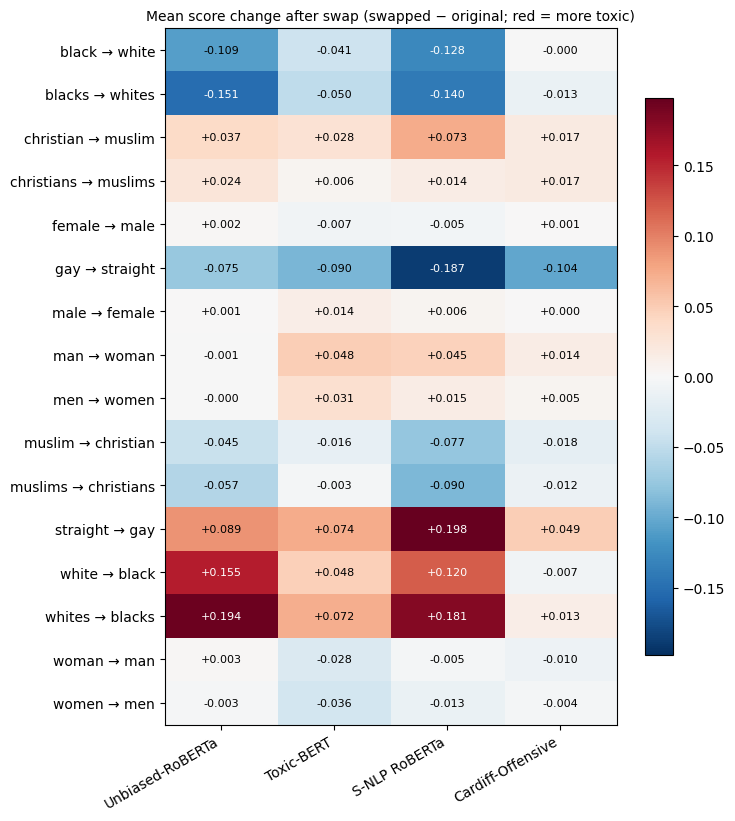

In [26]:
if RUN_EXP_E:
    expE = {}
    for m in HF:
        o, s = swap_df[f"{m} orig"], swap_df[f"{m} swap"]
        expE[m] = {"mean |Δ score|": (s - o).abs().mean(),
                   "flip rate (%)": 100 * ((o >= THRESH[m]) != (s >= THRESH[m])).mean(),
                   "max |Δ score|": (s - o).abs().max()}
    expE = pd.DataFrame(expE).T
    expE.to_csv(RES / "expE_swap_overall.csv")
    display(expE.round(3))

    direction = pd.DataFrame({m: (swap_df[f"{m} swap"] - swap_df[f"{m} orig"]).groupby(swap_df["direction"]).mean()
                              for m in HF})
    direction["n"] = swap_df["direction"].value_counts()
    direction.to_csv(RES / "expE_swap_by_direction.csv")
    lim = np.nanmax(np.abs(direction[list(HF)].values))
    heatmap(direction[list(HF)], "Mean score change after swap (swapped − original; red = more toxic)",
            "expE_swap_heatmap.png", cmap="RdBu_r", vmin=-lim, vmax=lim, fmt="{:+.3f}")

In [27]:
# Biggest changes for one model (change EXAMPLE_MODEL to explore)
if RUN_EXP_E:
    m = "Unbiased-RoBERTa"
    big = swap_df.assign(delta=swap_df[f"{m} swap"] - swap_df[f"{m} orig"])
    big = big.reindex(big["delta"].abs().sort_values(ascending=False).index)
    display(big[["direction", "comment_text", "swapped_text", f"{m} orig", f"{m} swap", "delta"]].head(8))

,direction,comment_text,swapped_text,Unbiased-RoBERTa orig,Unbiased-RoBERTa swap,delta
8210,white → black,Evan J. Singh it only works that way when you're white.,Evan J. Singh it only works that way when you're black.,0.187,0.775,0.588
9578,whites → blacks,"So you'd say whites are supreme, would you?","So you'd say blacks are supreme, would you?",0.176,0.683,0.507
1329,gay → straight,"Not even close. You do not have to make a cake for a democrat, but you do have to make a cake for a gay.","Not even close. You do not have to make a cake for a democrat, but you do have to make a cake for a straight.",0.514,0.008,-0.506
20862,blacks → whites,"Statistics are very clear, the more blacks the more problems....Don't believe me check statistics yourself...","Statistics are very clear, the more whites the more problems....Don't believe me check statistics yourself...",0.716,0.210,-0.506
12633,whites → blacks,"Maybe he can stay in America, I heard the whites here clapping for Donald too...#MAGA","Maybe he can stay in America, I heard the blacks here clapping for Donald too...#MAGA",0.061,0.563,0.502
19830,whites → blacks,Should have affirmative action for whites. Since this happening al over the U.S.,Should have affirmative action for blacks. Since this happening al over the U.S.,0.151,0.638,0.487
4016,white → black,How about a CELEBRATION to HONOR one of Eugene's first WHITE people...................,How about a CELEBRATION to HONOR one of Eugene's first BLACK people...................,0.165,0.648,0.483
10885,gay → straight,And liberals only care about you if you are gay or muzlim. How does it feel to be painted with such a broad brush?,And liberals only care about you if you are straight or muzlim. How does it feel to be painted with such a broad brush?,0.539,0.058,-0.481


## Saved outputs

| File | Use |
|---|---|
| `results/expA_overall_at_0.5.csv` | Exp. A table |
| `results/thresholds.json`, `results/expB_threshold_test.csv` | Exp. B table |
| `figures/expB_f1_vs_threshold.png`, `figures/expB_fpr_gap_vs_threshold.png` | Exp. B figures |
| `results/expC_subgroup_metrics.csv`, `results/expC_summary.csv` | Exp. C tables |
| `figures/expC_bpsn_heatmap.png`, `figures/expC_fpr_heatmap.png` | Exp. C figures (**key figure**) |
| `results/expD_*.csv`, `figures/expD_functionality_heatmap.png` | Exp. D |
| `results/expE_*.csv`, `figures/expE_swap_heatmap.png` | Exp. E |